In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv", parse_dates=["date"])

print("Shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Stores:", df["store"].nunique(), "| Items:", df["item"].nunique())

g = df.groupby(["store", "item"]).size()
print("Series:", len(g), "| Days per series (min, max):", g.min(), g.max())
print("Missing values:", df.isnull().sum().sum())
print("Zero-sales rows:", (df["sales"] == 0).sum(), "| Negative:", (df["sales"] < 0).sum())
print()
print(df["sales"].describe().round(2))
df.head()

Shape: (913000, 4)
Date range: 2013-01-01 to 2017-12-31
Stores: 10 | Items: 50
Series: 500 | Days per series (min, max): 1826 1826
Missing values: 0
Zero-sales rows: 1 | Negative: 0

count    913000.00
mean         52.25
std          28.80
min           0.00
25%          30.00
50%          47.00
75%          70.00
max         231.00
Name: sales, dtype: float64


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


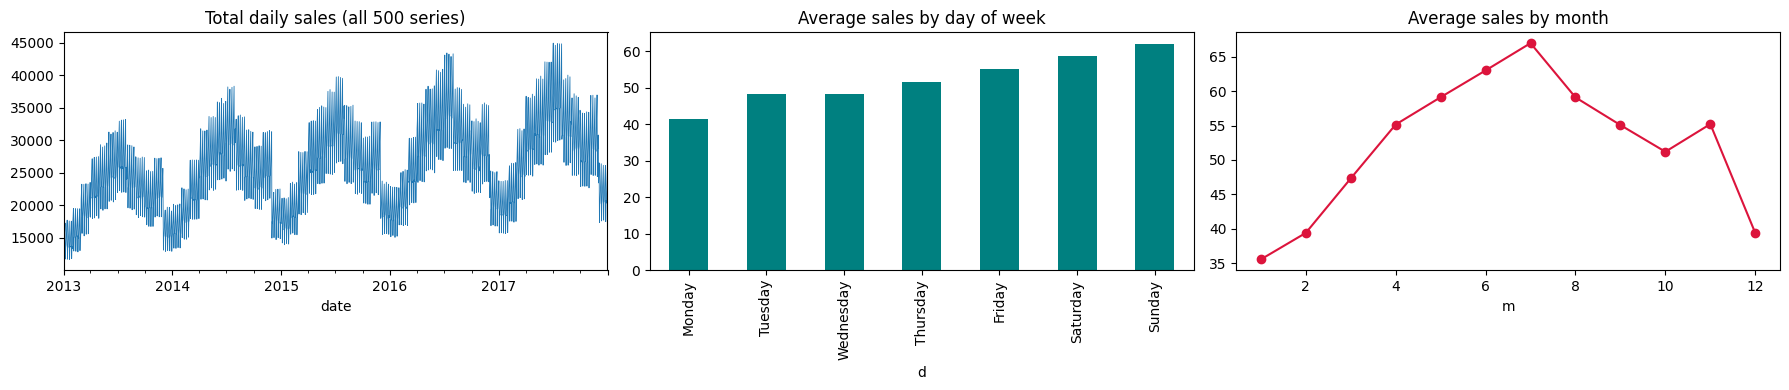

In [2]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

df.groupby("date")["sales"].sum().plot(ax=ax[0], linewidth=0.6)
ax[0].set_title("Total daily sales (all 500 series)")

df.assign(d=df["date"].dt.day_name()).groupby("d")["sales"].mean().reindex(days).plot(kind="bar", ax=ax[1], color="teal")
ax[1].set_title("Average sales by day of week")

df.assign(m=df["date"].dt.month).groupby("m")["sales"].mean().plot(marker="o", ax=ax[2], color="crimson")
ax[2].set_title("Average sales by month")

plt.tight_layout()
plt.savefig("demand_eda.png", dpi=150)
plt.show()

In [3]:
wide = df.pivot_table(index="date", columns=["store", "item"], values="sales")
H = pd.Timedelta(days=92)
fold_starts = pd.to_datetime(["2016-10-01", "2017-01-01", "2017-04-01", "2017-07-01"])

def weekday_profile(train, hdates, weeks=4):
    last = train.iloc[-7 * weeks:]
    prof = last.groupby(last.index.dayofweek).mean()
    return pd.DataFrame(prof.loc[hdates.dayofweek].values, index=hdates, columns=train.columns)

def last_year_scaled(train, hdates):
    ly = train.reindex(hdates - pd.Timedelta(days=364))
    recent = train.iloc[-91:].sum()
    prev = train.reindex(train.index[-91:] - pd.Timedelta(days=364)).sum()
    growth = recent / prev
    return pd.DataFrame(ly.values * growth.values, index=hdates, columns=train.columns)

def wape(a, f): return np.abs(a.values - f.values).sum() / a.values.sum()
def bias(a, f): return (f.values - a.values).sum() / a.values.sum()
def mase(train, a, f):
    scale = (train - train.shift(7)).abs().mean()
    return ((a - f).abs().mean() / scale).mean()

rows = []
for start in fold_starts:
    train = wide.loc[:start - pd.Timedelta(days=1)]
    actual = wide.loc[start:start + H - pd.Timedelta(days=1)]
    hd = actual.index
    for name, fc in [("Weekday profile (last 4 wks)", weekday_profile(train, hd)),
                     ("Last year x growth", last_year_scaled(train, hd))]:
        rows.append({"fold_start": start.date(), "model": name,
                     "WAPE": wape(actual, fc), "Bias": bias(actual, fc),
                     "MASE": mase(train, actual, fc)})

res = pd.DataFrame(rows)
print(res.round(4).to_string(index=False))
print()
print(res.groupby("model")[["WAPE", "Bias", "MASE"]].mean().round(4))
res.to_csv("baseline_results.csv", index=False)

fold_start                        model   WAPE    Bias   MASE
2016-10-01 Weekday profile (last 4 wks) 0.1997  0.1362 1.2609
2016-10-01           Last year x growth 0.1592  0.0007 1.0374
2017-01-01 Weekday profile (last 4 wks) 0.1743 -0.0798 0.9719
2017-01-01           Last year x growth 0.1756  0.0557 1.0026
2017-04-01 Weekday profile (last 4 wks) 0.2126 -0.2021 1.6760
2017-04-01           Last year x growth 0.1369 -0.0031 1.1327
2017-07-01 Weekday profile (last 4 wks) 0.1317  0.0422 1.0832
2017-07-01           Last year x growth 0.1351 -0.0051 1.1319

                                WAPE    Bias    MASE
model                                               
Last year x growth            0.1517  0.0120  1.0761
Weekday profile (last 4 wks)  0.1796 -0.0259  1.2480


In [4]:
import lightgbm as lgb

d = df.sort_values(["store", "item", "date"]).reset_index(drop=True)
g = d.groupby(["store", "item"])["sales"]

d["lag_364"] = g.shift(364)
d["ly_wk"] = g.transform(lambda s: s.rolling(7, center=True).mean().shift(364))
d["lvl_91"] = g.transform(lambda s: s.rolling(91).mean().shift(92))
d["lvl_91_ly"] = g.transform(lambda s: s.rolling(91).mean().shift(92 + 364))
d["growth"] = d["lvl_91"] / d["lvl_91_ly"]

d["dow"] = d["date"].dt.dayofweek
d["month"] = d["date"].dt.month
d["dom"] = d["date"].dt.day
d["woy"] = d["date"].dt.isocalendar().week.astype(int)
d["doy"] = d["date"].dt.dayofyear

feats = ["store", "item", "dow", "month", "dom", "woy", "doy",
         "lag_364", "ly_wk", "lvl_91", "lvl_91_ly", "growth"]
params = dict(objective="poisson", n_estimators=400, learning_rate=0.05, num_leaves=63,
              min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              n_jobs=-1, random_state=42, verbose=-1)

rows = []
for start in fold_starts:
    end = start + H
    tr = d[d["date"] < start].dropna(subset=feats)
    te = d[(d["date"] >= start) & (d["date"] < end)].copy()
    m = lgb.LGBMRegressor(**params)
    m.fit(tr[feats], tr["sales"], categorical_feature=["store", "item"])
    te["pred"] = m.predict(te[feats])
    actual = wide.loc[start:end - pd.Timedelta(days=1)]
    fc = te.pivot_table(index="date", columns=["store", "item"], values="pred").reindex(columns=actual.columns)
    train_w = wide.loc[:start - pd.Timedelta(days=1)]
    rows.append({"fold_start": start.date(), "model": "LightGBM",
                 "WAPE": wape(actual, fc), "Bias": bias(actual, fc),
                 "MASE": mase(train_w, actual, fc)})
    print("done fold", start.date())

res_lgb = pd.DataFrame(rows)
print(res_lgb.round(4).to_string(index=False))
print()
summary = pd.concat([res, res_lgb]).groupby("model")[["WAPE", "Bias", "MASE"]].mean().round(4)
print(summary.sort_values("WAPE"))
print()
print(pd.Series(m.feature_importances_, index=feats).sort_values(ascending=False))
res_lgb.to_csv("lgbm_results.csv", index=False)

done fold 2016-10-01
done fold 2017-01-01
done fold 2017-04-01
done fold 2017-07-01
fold_start    model   WAPE    Bias   MASE
2016-10-01 LightGBM 0.1135 -0.0116 0.7385
2017-01-01 LightGBM 0.1198  0.0155 0.6864
2017-04-01 LightGBM 0.0994  0.0048 0.8197
2017-07-01 LightGBM 0.0985 -0.0062 0.8233

                                WAPE    Bias    MASE
model                                               
LightGBM                      0.1078  0.0006  0.7670
Last year x growth            0.1517  0.0120  1.0761
Weekday profile (last 4 wks)  0.1796 -0.0259  1.2480

ly_wk        3806
lag_364      3337
month        3062
dow          2692
item         2476
doy          2026
lvl_91       2011
lvl_91_ly    1832
growth       1019
store         937
woy           934
dom           668
dtype: int32


In [5]:
test_start = pd.Timestamp("2017-10-01")
all_starts = list(fold_starts) + [test_start]
parts = []
for start in all_starts:
    end = start + H
    tr = d[d["date"] < start].dropna(subset=feats)
    te = d[(d["date"] >= start) & (d["date"] < end)].copy()
    m = lgb.LGBMRegressor(**params)
    m.fit(tr[feats], tr["sales"], categorical_feature=["store", "item"])
    te["pred"] = m.predict(te[feats])
    te["fold"] = "test" if start == test_start else str(start.date())
    parts.append(te[["date", "store", "item", "sales", "pred", "fold"]])
    print("done", start.date())

oof = pd.concat(parts, ignore_index=True)
oof.to_csv("oof_predictions.csv", index=False)

# --- Error of 14-day cumulative demand, backtest folds only (test fold excluded) ---
W = 14
rel_list, agg_rows = [], []
for f, grp in oof[oof["fold"] != "test"].groupby("fold"):
    A = grp.pivot_table(index="date", columns=["store", "item"], values="sales")
    F = grp.pivot_table(index="date", columns=["store", "item"], values="pred")
    A14 = A.rolling(W).sum().dropna()
    F14 = F.rolling(W).sum().dropna()
    rel_list.append((A14 - F14) / F14)
    agg_rows.append({"fold": f,
                     "daily_WAPE": np.abs(A.values - F.values).sum() / A.values.sum(),
                     "14day_WAPE": np.abs(A14.values - F14.values).sum() / A14.values.sum()})
print(pd.DataFrame(agg_rows).round(4).to_string(index=False))
print()

# --- Safety factors by volume segment ---
vol = wide.loc[:"2016-09-30"].mean()
seg = pd.qcut(vol, 3, labels=["Low volume", "Mid volume", "High volume"])
levels = [0.90, 0.95, 0.98, 0.99]
out = []
for sname in seg.cat.categories:
    cols = seg.index[seg == sname]
    vals = np.concatenate([r.reindex(columns=cols).values.ravel() for r in rel_list])
    out.append({"segment": sname, "series": len(cols),
                **{f"P{int(l * 100)}": np.quantile(vals, l) for l in levels},
                "std": vals.std()})
safety = pd.DataFrame(out).set_index("segment").round(3)
print(safety)
safety.to_csv("safety_factors.csv")

done 2016-10-01
done 2017-01-01
done 2017-04-01
done 2017-07-01
done 2017-10-01
      fold  daily_WAPE  14day_WAPE
2016-10-01      0.1135      0.0387
2017-01-01      0.1198      0.0401
2017-04-01      0.0994      0.0313
2017-07-01      0.0985      0.0322

             series    P90    P95    P98    P99    std
segment                                               
Low volume      167  0.077  0.102  0.131  0.152  0.062
Mid volume      166  0.055  0.072  0.092  0.106  0.046
High volume     167  0.052  0.068  0.086  0.100  0.040


In [6]:
oo = oof[oof["fold"] == "test"]
A = oo.pivot_table(index="date", columns=["store", "item"], values="sales").reindex(columns=wide.columns)
F = oo.pivot_table(index="date", columns=["store", "item"], values="pred").reindex(columns=wide.columns)
Av, Fv = A.values, F.values
T, N = Av.shape
L, R, WARM = 7, 7, 14
PROT = L + R

hist = wide.loc[:"2017-12-31"].values
t0 = wide.index.get_loc(test_start)

train_pre = wide.loc[:test_start - pd.Timedelta(days=1)]
Bv = last_year_scaled(train_pre, A.index).values

levels_all = [0.05, 0.20, 0.50, 0.80, 0.90, 0.95, 0.98, 0.99, 0.995]
q = {}
for sname in seg.cat.categories:
    cols = seg.index[seg == sname]
    vals = np.concatenate([r.reindex(columns=cols).values.ravel() for r in rel_list])
    q[sname] = {l: np.quantile(vals, l) for l in levels_all}
seg_arr = np.array(seg.astype(str))
def mult(level): return np.array([q[s][level] for s in seg_arr])
def cover(M, t): return M[t:t + PROT].sum(axis=0)
print("setup done:", T, "days,", N, "series")

setup done: 92 days, 500 series


In [7]:
def simulate(S_fn):
    onhand = S_fn(0).copy()
    pipe = np.zeros((T + L + 1, N))
    inv, lost = np.zeros((T, N)), np.zeros((T, N))
    for t in range(T):
        onhand = onhand + pipe[t]
        if t % R == 0:
            ip = onhand + pipe[t + 1:].sum(axis=0)
            pipe[t + L] += np.maximum(0, S_fn(t) - ip)
        sold = np.minimum(onhand, Av[t])
        lost[t] = Av[t] - sold
        onhand = onhand - sold
        inv[t] = onhand
    return inv[WARM:], lost[WARM:]

HOLD = 10 * 0.25 / 365   # ASSUMPTION: $10 unit cost, 25% annual holding rate
LOST = 4.0               # ASSUMPTION: $4 margin lost per unit not sold

def metrics(name, param, inv, lost):
    dem = Av[WARM:].sum()
    return {"policy": name, "setting": param,
            "fill_rate_%": 100 * (1 - lost.sum() / dem),
            "stockout_rate_%": 100 * (lost > 0).mean(),
            "avg_inventory_units": inv.sum(axis=1).mean(),
            "total_cost_$": HOLD * inv.sum() + LOST * lost.sum()}

rows = []
for b in [round(float(x), 2) + 0.0 for x in np.arange(-0.30, 0.55, 0.05)]:
    inv, lost = simulate(lambda t, b=b: hist[t0 + t - 28:t0 + t].mean(axis=0) * PROT * (1 + b))
    rows.append(metrics("1 Rule of thumb", f"buffer {b:+.0%}", inv, lost))
    inv, lost = simulate(lambda t, b=b: cover(Bv, t) * (1 + b))
    rows.append(metrics("2 Last-yr baseline", f"buffer {b:+.0%}", inv, lost))
for l in levels_all:
    inv, lost = simulate(lambda t, l=l: cover(Fv, t) * (1 + mult(l)))
    rows.append(metrics("3 LightGBM", f"P{l*100:g}", inv, lost))

sim = pd.DataFrame(rows)
sim.to_csv("simulation_results.csv", index=False)
print("simulation done:", len(sim), "runs saved")

simulation done: 43 runs saved


Lowest-cost setting per policy:
            policy     setting  fill%  stockout%  avg_inv   cost$
   1 Rule of thumb buffer +15%  99.96       0.17 171971.0 95097.0
2 Last-yr baseline buffer +15%  99.94       0.32 137791.0 78532.0
        3 LightGBM         P99  99.96       0.19 122145.0 68528.0

1 Rule of thumb cost vs rule of thumb: +0.0%
2 Last-yr baseline cost vs rule of thumb: -17.4%
3 LightGBM cost vs rule of thumb: -27.9%

Avg inventory (units) needed to reach each fill rate:
                  rule  baseline  LightGBM  less_vs_rule%  less_vs_base%
fill_target%                                                            
98.0          119928.1   93582.3   87928.3           26.7            6.0
99.0          131448.2  101446.1   94787.2           27.9            6.6
99.5          143874.2  113164.0  101428.0           29.5           10.4


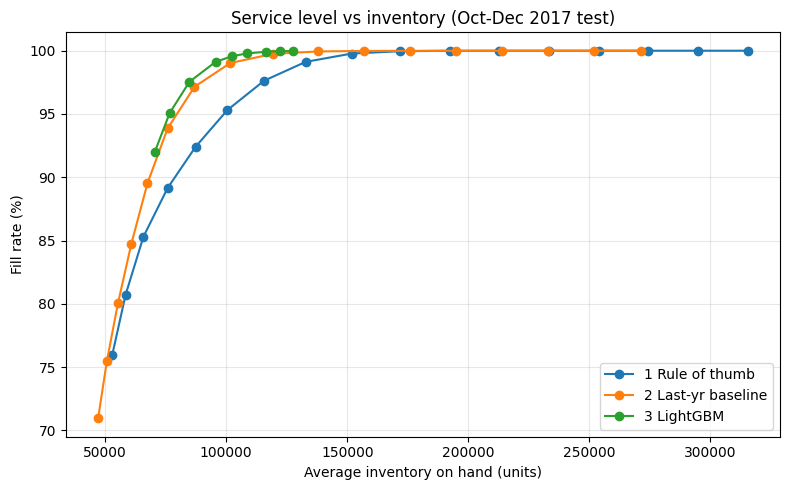

In [8]:
best = sim.loc[sim.groupby("policy")["total_cost_$"].idxmin()]
show = best[["policy", "setting", "fill_rate_%", "stockout_rate_%", "avg_inventory_units", "total_cost_$"]].copy()
show.columns = ["policy", "setting", "fill%", "stockout%", "avg_inv", "cost$"]
print("Lowest-cost setting per policy:")
print(show.round({"fill%": 2, "stockout%": 2, "avg_inv": 0, "cost$": 0}).to_string(index=False))
rule_cost = best.loc[best["policy"].str.startswith("1"), "total_cost_$"].iloc[0]
print()
for _, r in best.iterrows():
    print(r["policy"], "cost vs rule of thumb:", f"{100 * (r['total_cost_$'] / rule_cost - 1):+.1f}%")

tab = []
for target in [98, 99, 99.5]:
    row = {"fill_target%": target}
    for p, g in sim.groupby("policy"):
        g = g[g["fill_rate_%"] < 99.99].sort_values("fill_rate_%")
        ok = g["fill_rate_%"].min() <= target <= g["fill_rate_%"].max()
        row[p] = np.interp(target, g["fill_rate_%"], g["avg_inventory_units"]) if ok else np.nan
    tab.append(row)
need = pd.DataFrame(tab).set_index("fill_target%")
need.columns = ["rule", "baseline", "LightGBM"]
need["less_vs_rule%"] = 100 * (1 - need["LightGBM"] / need["rule"])
need["less_vs_base%"] = 100 * (1 - need["LightGBM"] / need["baseline"])
print("\nAvg inventory (units) needed to reach each fill rate:")
print(need.round(1).to_string())

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 5))
for p, g in sim.groupby("policy"):
    g = g.sort_values("avg_inventory_units")
    ax.plot(g["avg_inventory_units"], g["fill_rate_%"], marker="o", label=p)
ax.set_xlabel("Average inventory on hand (units)")
ax.set_ylabel("Fill rate (%)")
ax.set_title("Service level vs inventory (Oct-Dec 2017 test)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("frontier.png", dpi=150); plt.show()

In [9]:
dem = Av[WARM:].sum()
days = T - WARM
sim["inv_days"] = sim["avg_inventory_units"] * days
sim["lost_units"] = (1 - sim["fill_rate_%"] / 100) * dem

rows = []
for rate in [0.15, 0.25, 0.40]:
    for margin in [2, 4, 8]:
        hold = 10 * rate / 365
        s = sim.assign(cost=hold * sim["inv_days"] + margin * sim["lost_units"])
        b = s.loc[s.groupby("policy")["cost"].idxmin()].set_index("policy")
        r = b.loc["1 Rule of thumb", "cost"]
        k = b.loc["2 Last-yr baseline", "cost"]
        m = b.loc["3 LightGBM", "cost"]
        rows.append({"hold%": int(rate * 100), "lost$": margin,
                     "rule$": round(r), "base$": round(k), "lgbm$": round(m),
                     "vs_rule%": round(100 * (m / r - 1), 1),
                     "vs_base%": round(100 * (m / k - 1), 1),
                     "lgbm_setting": b.loc["3 LightGBM", "setting"]})
sens6 = pd.DataFrame(rows)
print(sens6.to_string(index=False))
sens6.to_csv("cost_sensitivity.csv", index=False)

 hold%  lost$  rule$  base$  lgbm$  vs_rule%  vs_base% lgbm_setting
    15      2  56736  46628  40789     -28.1     -12.5          P99
    15      4  58347  49087  42425     -27.3     -13.6          P99
    15      8  61570  53237  44220     -28.2     -16.9        P99.5
    25      2  90607  74355  65712     -27.5     -11.6          P98
    25      4  95097  78532  68528     -27.9     -12.7          P99
    25      8  98320  83451  71499     -27.3     -14.3        P99.5
    40      2 139291 112548 101886     -26.9      -9.5          P95
    40      4 148756 122701 106539     -28.4     -13.2          P98
    40      8 153444 127619 110953     -27.7     -13.1          P99
